In [3]:
import tensorflow as tf
import matplotlib.pyplot as plt
import os

# 1. Definición de rutas y variables globales (Variante del proyecto)
TRAIN_DIR = '../data/seg_train/seg_train'
TEST_DIR = '../data/seg_test/seg_test'
BATCH_SIZE = 32
IMG_SIZE = (64, 64) # Reducimos la resolución para el MLP
SEED = 42 # Semilla para asegurar reproducibilidad

# 2. Carga de datos usando generadores de Keras
print("Cargando datos de entrenamiento...")
train_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    shuffle=True,
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    seed=SEED
)

print("\nCargando datos de validación/test...")
test_dataset = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    shuffle=False,
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    seed=SEED
)

# Nombres de las clases detectadas
class_names = train_dataset.class_names
print(f"\nClases detectadas: {class_names}")

# 3. Capa de normalización (escala los píxeles de 0-255 a 0-1)
normalization_layer = tf.keras.layers.Rescaling(1./255)

# Aplicar normalización a los datasets
train_dataset = train_dataset.map(lambda x, y: (normalization_layer(x), y))
test_dataset = test_dataset.map(lambda x, y: (normalization_layer(x), y))

Cargando datos de entrenamiento...
Found 14034 files belonging to 6 classes.

Cargando datos de validación/test...
Found 3000 files belonging to 6 classes.

Clases detectadas: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [4]:
from tensorflow.keras import models, layers

# 1. Definición de la arquitectura MLP
model = models.Sequential()

# Capa de aplanado: Obligatoria en MLP para pasar de 2D (imagen) a un vector 1D
model.add(layers.Flatten(input_shape=(64, 64, 3)))

# Capas Ocultas: Estructura en embudo
model.add(layers.Dense(512, activation='relu'))
model.add(layers.Dropout(0.3)) # Apaga el 30% de neuronas al azar para evitar que memorice (sobreajuste)

model.add(layers.Dense(256, activation='relu'))
model.add(layers.Dropout(0.3))

model.add(layers.Dense(128, activation='relu'))

# Capa de Salida: 6 neuronas por nuestras 6 clases de escenarios naturales
model.add(layers.Dense(6, activation='softmax'))

# 2. Compilación del modelo
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Imprimir el resumen de la arquitectura
model.summary()

c:\Users\gtabe\Documents\GitHub\TLY1101-EP1-Intel-Dataset\.venv\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     6,291,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,456,966 (24.63 MB)

 Trainable params: 6,456,966 (24.63 MB)

 Non-trainable params: 0 (0.00 B)

Iniciando el entrenamiento del modelo...
Epoch 1/20


c:\Users\gtabe\Documents\GitHub\TLY1101-EP1-Intel-Dataset\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


439/439 ━━━━━━━━━━━━━━━━━━━━ 29s 62ms/step - accuracy: 0.3484 - loss: 1.7529 - val_accuracy: 0.4090 - val_loss: 1.4356
Epoch 2/20
439/439 ━━━━━━━━━━━━━━━━━━━━ 27s 62ms/step - accuracy: 0.4139 - loss: 1.4489 - val_accuracy: 0.4727 - val_loss: 1.3614
Epoch 3/20
439/439 ━━━━━━━━━━━━━━━━━━━━ 27s 62ms/step - accuracy: 0.4269 - loss: 1.4190 - val_accuracy: 0.4593 - val_loss: 1.3523
Epoch 4/20
439/439 ━━━━━━━━━━━━━━━━━━━━ 28s 63ms/step - accuracy: 0.4386 - loss: 1.3847 - val_accuracy: 0.4910 - val_loss: 1.3508
Epoch 5/20
439/439 ━━━━━━━━━━━━━━━━━━━━ 28s 65ms/step - accuracy: 0.4627 - loss: 1.3558 - val_accuracy: 0.4800 - val_loss: 1.3577
Epoch 6/20
439/439 ━━━━━━━━━━━━━━━━━━━━ 28s 63ms/step - accuracy: 0.4584 - loss: 1.3580 - val_accuracy: 0.5093 - val_loss: 1.2883
Epoch 7/20
439/439 ━━━━━━━━━━━━━━━━━━━━ 28s 64ms/step - accuracy: 0.4668 - loss: 1.3258 - val_accuracy: 0.5047 - val_loss: 1.3016
Epoch 8/20
439/439 ━━━━━━━━━━━━━━━━━━━━ 27s 62ms/step - accuracy: 0.4788 - loss: 1.3215 - val_accurac

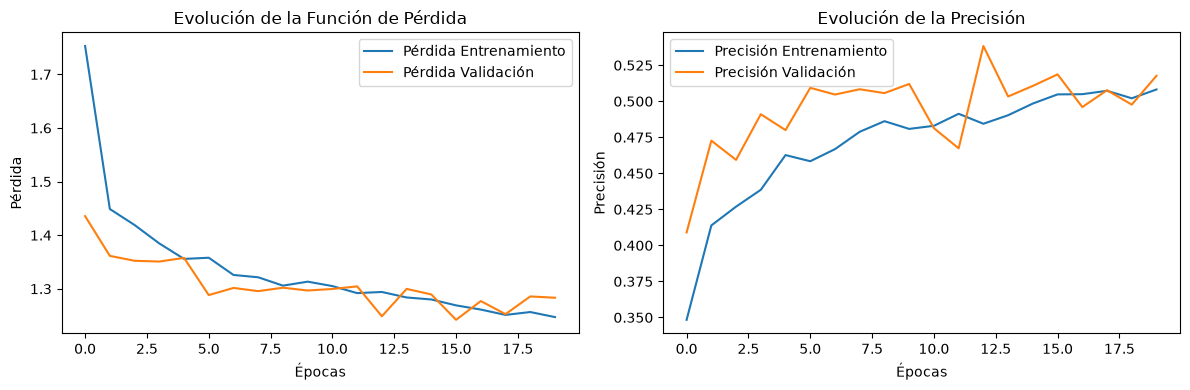

In [5]:
import matplotlib.pyplot as plt

# 1. Configurar la cantidad de épocas (vueltas completas de estudio)
EPOCHS = 20

print("Iniciando el entrenamiento del modelo...")
# La variable history guardará todo el proceso para poder graficarlo después
history = model.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=EPOCHS
)

# 2. Graficar el proceso de aprendizaje (Loss y Accuracy)
plt.figure(figsize=(12, 4))

# Gráfico de Pérdida (Loss)
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Pérdida Entrenamiento')
plt.plot(history.history['val_loss'], label='Pérdida Validación')
plt.title('Evolución de la Función de Pérdida')
plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.legend()

# Gráfico de Precisión (Accuracy)
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Precisión Entrenamiento')
plt.plot(history.history['val_accuracy'], label='Precisión Validación')
plt.title('Evolución de la Precisión')
plt.xlabel('Épocas')
plt.ylabel('Precisión')
plt.legend()

plt.tight_layout()
plt.show()

Generando predicciones sobre el set de validación (esto tomará unos segundos)...

--- REPORTE DE CLASIFICACIÓN ---
              precision    recall  f1-score   support

   buildings       0.31      0.43      0.37       437
      forest       0.66      0.77      0.71       474
     glacier       0.67      0.45      0.54       553
    mountain       0.55      0.59      0.57       525
         sea       0.40      0.14      0.20       510
      street       0.51      0.73      0.60       501

    accuracy                           0.52      3000
   macro avg       0.52      0.52      0.50      3000
weighted avg       0.52      0.52      0.50      3000



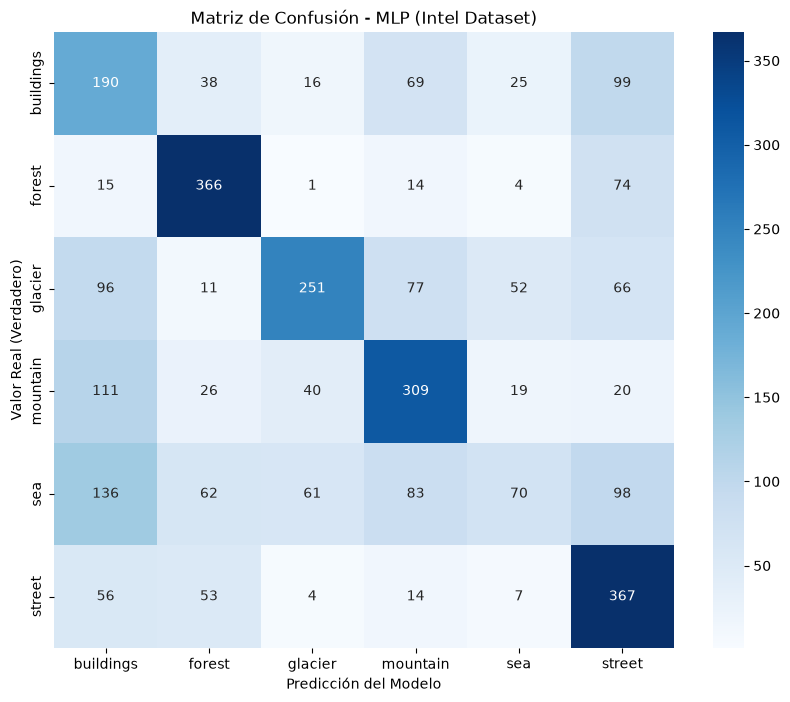

In [7]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# 1. Extraer las etiquetas reales y generar las predicciones
y_true = []
y_pred_probs = []

print("Generando predicciones sobre el set de validación (esto tomará unos segundos)...")
for images, labels in test_dataset:
    y_true.extend(labels.numpy())
    # El modelo predice probabilidades para cada clase
    preds = model.predict(images, verbose=0) 
    y_pred_probs.extend(preds)

y_true = np.array(y_true)
# Elegimos la clase con la probabilidad más alta
y_pred = np.argmax(y_pred_probs, axis=1)

# 2. Imprimir el Reporte de Clasificación (Precision, Recall, F1-Score)
print("\n--- REPORTE DE CLASIFICACIÓN ---")
print(classification_report(y_true, y_pred, target_names=class_names))

# 3. Dibujar la Matriz de Confusión
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names)
plt.title('Matriz de Confusión - MLP (Intel Dataset)')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real (Verdadero)')
plt.show()

In [8]:
# Guardar el modelo entrenado con todos sus pesos
model.save('../models/mlp_intel_model.keras')
print("Modelo guardado exitosamente en la carpeta 'models'")

Modelo guardado exitosamente en la carpeta 'models'
